In [1]:
# 1단계 ) 테스트 이미지 가져오기
import shutil
from pathlib import Path

SRC = Path.home() / "ai_vision/Vision_AI_Class/교과 9 openCV 규칙기반 머신비전/10일 수업/3일차 데이터 이미지/day03"
TEST = Path("data/test")
TEST.mkdir(parents=True, exist_ok=True)

for f in sorted(SRC.glob("cap_o*/*.jpg")):
    shutil.copy(f, TEST / f.name)
    print("복사:", f.name)

print(sorted(p.name for p in TEST.glob("*.jpg")))

복사: cap_off_001.jpg
복사: cap_off_002.jpg
복사: cap_off_003.jpg
복사: cap_on_001.jpg
복사: cap_on_002.jpg
복사: cap_on_003.jpg
['cap_off_001.jpg', 'cap_off_002.jpg', 'cap_off_003.jpg', 'cap_on_001.jpg', 'cap_on_002.jpg', 'cap_on_003.jpg']


cap_on.jpg       | 크기 (198, 213) | 어두운 5%    25 | 중간값    41
cap_off.jpg      | 크기 (198, 213) | 어두운 5%    28 | 중간값   121
cap_off_001.jpg  | 크기 (199, 235) | 어두운 5%    64 | 중간값   157
cap_off_002.jpg  | 크기 (219, 226) | 어두운 5%    63 | 중간값   153
cap_off_003.jpg  | 크기 (182, 199) | 어두운 5%    61 | 중간값   154
cap_on_001.jpg   | 크기 (213, 232) | 어두운 5%    54 | 중간값   151
cap_on_002.jpg   | 크기 (204, 223) | 어두운 5%    53 | 중간값    85
cap_on_003.jpg   | 크기 (200, 213) | 어두운 5%    55 | 중간값   141


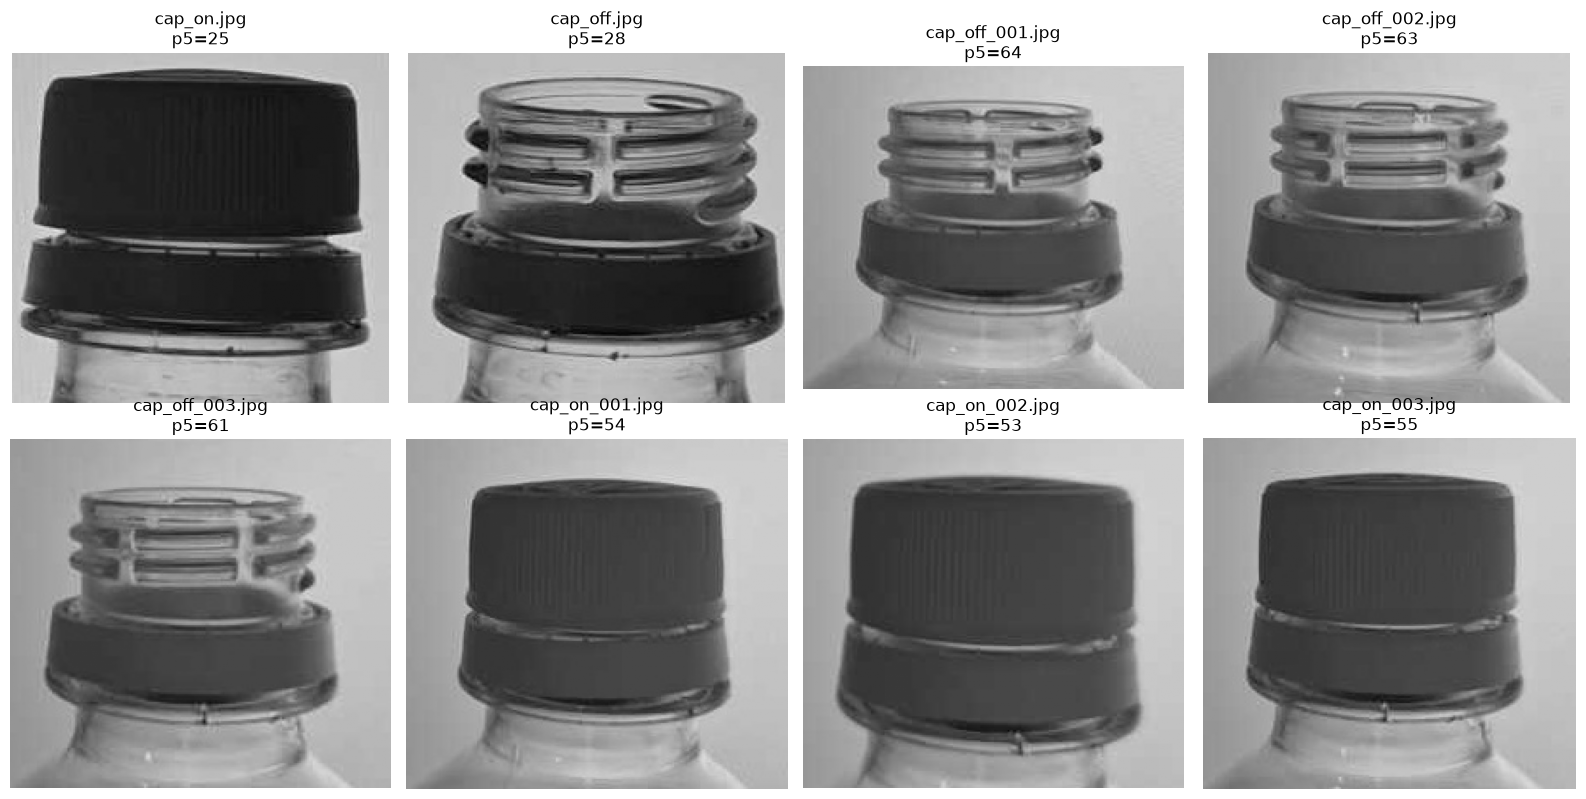

In [2]:
##2단계 8장을 한 화면에서 보고 밝기 비교하기
import cv2
import numpy as np
import matplotlib.pyplot as plt

REF = Path("samples/day03/reference")
files = [REF / "cap_on.jpg", REF / "cap_off.jpg"] + sorted(TEST.glob("*.jpg"))

plt.figure(figsize=(16, 8))
for i, f in enumerate(files):
    gray = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2GRAY)
    p5, p50 = np.percentile(gray, [5, 50])
    print(f"{f.name:16} | 크기 {gray.shape} | 어두운 5% {p5:5.0f} | 중간값 {p50:5.0f}")

    plt.subplot(2, 4, i + 1)
    plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
    plt.title(f"{f.name}\np5={p5:.0f}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [3]:
#3단계: 교재 방식 vs 고정 T=50을 테스트 6장으로 채점하기
def area_ratio(gray, method):
    """이진화 → Opening/Closing → 가장 큰 덩어리 면적 비율"""
    if method == "otsu":
        _, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    else:   # "fixed50"
        n = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
        _, b = cv2.threshold(n, 50, 255, cv2.THRESH_BINARY_INV)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, k)
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, k)
    contours, _ = cv2.findContours(b, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return 0.0
    return max(cv2.contourArea(c) for c in contours) / b.size

def load_gray(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2GRAY)

for method in ["otsu", "fixed50"]:
    on_r  = area_ratio(load_gray(REF / "cap_on.jpg"), method)
    off_r = area_ratio(load_gray(REF / "cap_off.jpg"), method)
    th = (on_r + off_r) / 2
    print(f"\n[{method}] 기준 ON {on_r:.3f} / OFF {off_r:.3f} → 판정 기준 {th:.3f}")

    correct = 0
    for f in sorted(TEST.glob("*.jpg")):
        r = area_ratio(load_gray(f), method)
        answer = "OK" if f.name.startswith("cap_on") else "NG"
        pred = "OK" if r >= th else "NG"
        correct += (pred == answer)
        print(f"  {f.name:16} 비율 {r:.3f} → {pred} (정답 {answer}) {'✅' if pred == answer else '❌'}")
    print(f"  정확도: {correct} / 6")


[otsu] 기준 ON 0.661 / OFF 0.459 → 판정 기준 0.560
  cap_off_001.jpg  비율 0.284 → NG (정답 NG) ✅
  cap_off_002.jpg  비율 0.290 → NG (정답 NG) ✅
  cap_off_003.jpg  비율 0.317 → NG (정답 NG) ✅
  cap_on_001.jpg   비율 0.438 → NG (정답 OK) ❌
  cap_on_002.jpg   비율 0.560 → OK (정답 OK) ✅
  cap_on_003.jpg   비율 0.457 → NG (정답 OK) ❌
  정확도: 4 / 6

[fixed50] 기준 ON 0.348 / OFF 0.160 → 판정 기준 0.254
  cap_off_001.jpg  비율 0.026 → NG (정답 NG) ✅
  cap_off_002.jpg  비율 0.025 → NG (정답 NG) ✅
  cap_off_003.jpg  비율 0.012 → NG (정답 NG) ✅
  cap_on_001.jpg   비율 0.114 → NG (정답 OK) ❌
  cap_on_002.jpg   비율 0.004 → NG (정답 OK) ❌
  cap_on_003.jpg   비율 0.054 → NG (정답 OK) ❌
  정확도: 3 / 6


## 3단계 결과: 기준선 채점 (테스트 6장)
- 교재 방식 (Otsu + 면적 비율): 4/6, OK→NG 2건, cap_on_002는 0.560으로 기준선과 같음(경계)
- 고정 T=50: 3/6, 뚜껑 있음 3장 모두 NG (뚜껑 밝기 p5 25 → 54로 올라가 못 잡음)
- 공통: FN(불량 통과) 0건, FP(정상품 폐기)만 발생
- 원인: 테스트 사진은 병 거리·위치가 달라 면적 비율이 작아짐 / 조명이 달라 뚜껑이 회색

In [4]:
# 4단계: 거리에 덜 흔들리는 특징 만들기 / 면적은 크기에 따라 변하니까, 크기 대신 모양을 보는 특징 사용
# 뚜껑 있음: 뚜껑은 꽉 찬 띠라서 대부분의 줄이 흰색으로 채워짐 → 값이 높음
# 뚜껑 없음: 나사산은 가는 줄이 듬성듬성 있어서 채워진 줄이 적어짐 → 값이 낮음

def solid_row_ratio(gray, fill=0.5):
    """Otsu 이진화 후, 위쪽 절반에서 흰색이 fill 이상 채워진 가로줄의 비율"""
    _, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, k)
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, k)
    top = b[: b.shape[0] // 2]          # 위쪽 절반만
    row_fill = (top > 0).mean(axis=1)    # 줄마다 흰색 비율
    return (row_fill > fill).mean()      # 꽉 찬 줄의 비율

on_s  = solid_row_ratio(load_gray(REF / "cap_on.jpg"))
off_s = solid_row_ratio(load_gray(REF / "cap_off.jpg"))
th_s = (on_s + off_s) / 2
print(f"기준 ON {on_s:.3f} / OFF {off_s:.3f} → 판정 기준 {th_s:.3f}")

results = []
for f in sorted(TEST.glob("*.jpg")):
    s = solid_row_ratio(load_gray(f))
    answer = "OK" if f.name.startswith("cap_on") else "NG"
    pred = "OK" if s >= th_s else "NG"
    results.append((f.name, s, answer, pred))
    print(f"  {f.name:16} 꽉 찬 줄 {s:.3f} → {pred} (정답 {answer}) {'✅' if pred == answer else '❌'}")

on_vals  = [s for _, s, a, _ in results if a == "OK"]
off_vals = [s for _, s, a, _ in results if a == "NG"]
print(f"정확도: {sum(a == p for _, _, a, p in results)} / 6")
print(f"마진 (ON 최소 − OFF 최대): {min(on_vals) - max(off_vals):.3f}")

기준 ON 0.869 / OFF 0.333 → 판정 기준 0.601
  cap_off_001.jpg  꽉 찬 줄 0.232 → NG (정답 NG) ✅
  cap_off_002.jpg  꽉 찬 줄 0.312 → NG (정답 NG) ✅
  cap_off_003.jpg  꽉 찬 줄 0.253 → NG (정답 NG) ✅
  cap_on_001.jpg   꽉 찬 줄 0.726 → OK (정답 OK) ✅
  cap_on_002.jpg   꽉 찬 줄 0.755 → OK (정답 OK) ✅
  cap_on_003.jpg   꽉 찬 줄 0.760 → OK (정답 OK) ✅
정확도: 6 / 6
마진 (ON 최소 − OFF 최대): 0.414


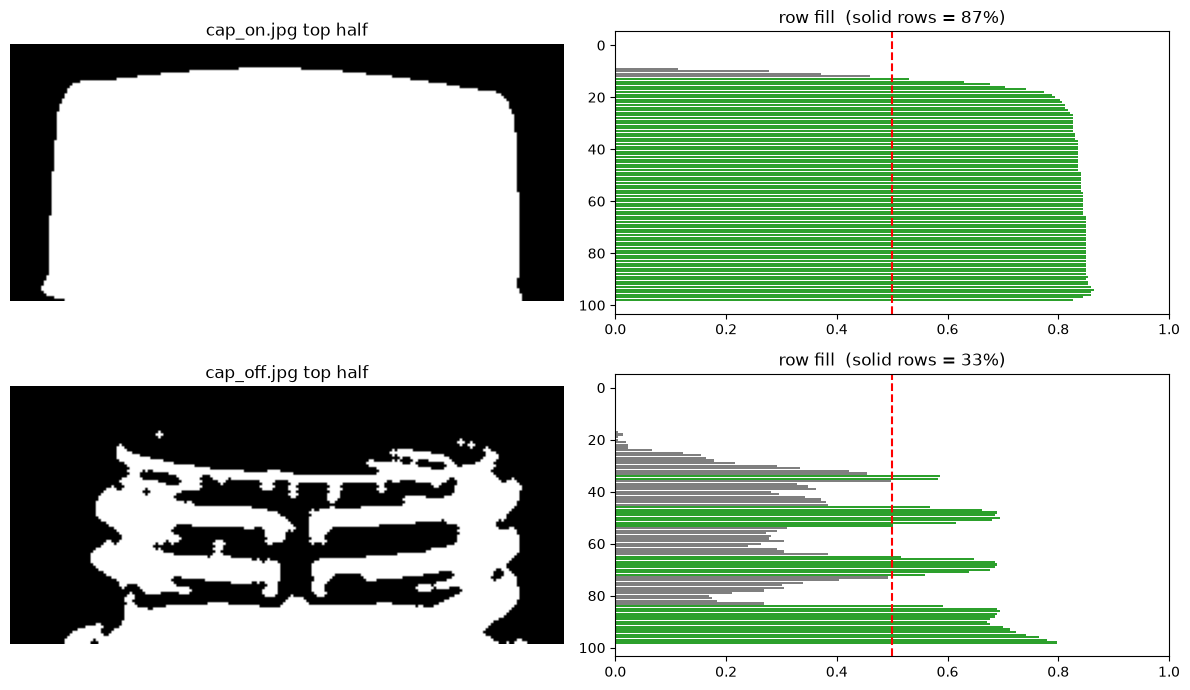

In [5]:
plt.figure(figsize=(12, 7))
for r, f in enumerate([REF / "cap_on.jpg", REF / "cap_off.jpg"]):
    gray = load_gray(f)
    _, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    b = cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    top = b[: b.shape[0] // 2]
    row_fill = (top > 0).mean(axis=1)

    plt.subplot(2, 2, r * 2 + 1)
    plt.imshow(top, cmap="gray"); plt.title(f"{f.name} top half"); plt.axis("off")

    plt.subplot(2, 2, r * 2 + 2)
    colors = ["tab:green" if v > 0.5 else "tab:gray" for v in row_fill]
    plt.barh(range(len(row_fill)), row_fill, color=colors)
    plt.axvline(0.5, color="red", linestyle="--")
    plt.gca().invert_yaxis() # 막대 순서를 이미지와 같게 위에서 아래로 맞춤
    plt.xlim(0, 1)
    plt.title(f"row fill  (solid rows = {(row_fill > 0.5).mean():.0%})")
plt.tight_layout()
plt.show()

   fill  threshold  ON_min  OFF_max accuracy  margin
0   0.3      0.712   0.745    0.475      6/6   0.271
1   0.4      0.631   0.736    0.385      6/6   0.351
2   0.5      0.601   0.726    0.312      6/6   0.414
3   0.6      0.561   0.708    0.128      6/6   0.579
4   0.7      0.449   0.000    0.064      4/6  -0.064
5   0.8      0.394   0.000    0.000      3/6   0.000


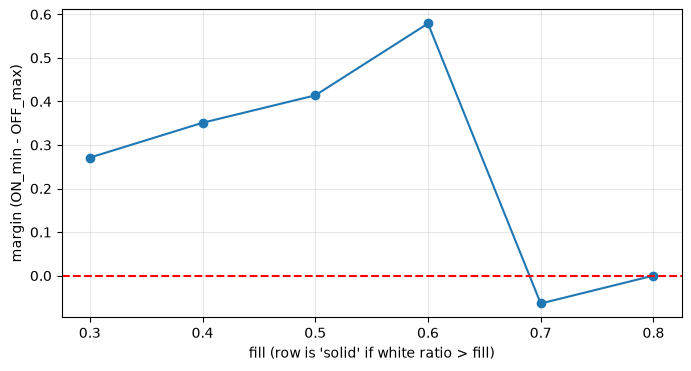

In [7]:
##5단계: "꽉 찬 줄" 기준(fill)을 바꿔가며 근거 남기기
import pandas as pd

OUT = Path("outputs/okng")
OUT.mkdir(parents=True, exist_ok=True)

rows = []
for fill in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    on_s  = solid_row_ratio(load_gray(REF / "cap_on.jpg"), fill)
    off_s = solid_row_ratio(load_gray(REF / "cap_off.jpg"), fill)
    th = (on_s + off_s) / 2

    on_vals, off_vals = [], []
    for f in sorted(TEST.glob("*.jpg")):
        s = solid_row_ratio(load_gray(f), fill)
        (on_vals if f.name.startswith("cap_on") else off_vals).append(s)

    acc = sum(v >= th for v in on_vals) + sum(v < th for v in off_vals)
    rows.append({"fill": fill, "threshold": round(th, 3),
                 "ON_min": round(min(on_vals), 3), "OFF_max": round(max(off_vals), 3),
                 "accuracy": f"{acc}/6", "margin": round(min(on_vals) - max(off_vals), 3)})

sweep_fill = pd.DataFrame(rows)
print(sweep_fill)
sweep_fill.to_csv(OUT / "fill_sweep.csv", index=False)

plt.figure(figsize=(8, 4))
plt.plot(sweep_fill["fill"], sweep_fill["margin"], marker="o")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("fill (row is 'solid' if white ratio > fill)")
plt.ylabel("margin (ON_min - OFF_max)")
plt.grid(alpha=0.3)
plt.savefig(OUT / "fill_sweep.png")
plt.show()

## 5단계 결론: fill 선택
- 방법: fill 0.3~0.8 스윕, 기준 2장으로 판정선을 정하고 강사 테스트 6장으로 정확도·마진 확인
- 결과: 0.3~0.6 모두 6/6, 마진 최대 0.6(0.579) / 0.7부터 붕괴(테스트 ON 줄 채움이 0.6~0.69라 못 셈)
- 선택: fill = 0.5 (안정 구간 가운데, 마진 0.414)
- 이유: 0.6은 절벽(0.7) 바로 앞 → 뚜껑이 더 작게 찍히면 위험
- 비교: 교재 방식 마진 0.121(4/6) → 꽉 찬 줄 비율 마진 0.414(6/6)
- 주의: 테스트 6장을 보고 정했으므로 이 6장은 validation. 최종 성능은 직접 찍은 새 사진으로 확인 필요
- 증거: outputs/okng/fill_sweep.csv, fill_sweep.png

In [10]:
%%writefile src/cap_inspector_v2.py
#6단계: 검사 함수 개선판 파일 만들기
"""병뚜껑 검사 개선판 (v2).

교재 cap_inspector.py와 같은 함수 이름을 유지해서 FastAPI에서 import만 바꾸면 되게 만들었다.
바뀐 점
  1. 판정 특징: 가장 큰 덩어리 면적 비율 -> 위쪽 절반의 '꽉 찬 줄 비율'
     (병 거리·크기가 바뀌어도 덜 흔들림, 근거: outputs/okng/fill_sweep.csv)
  2. 기준선 근처는 CHECK(확인 필요)로 분류
  3. ROI가 비정상(거의 다 흰색/검은색)이면 CHECK
  4. 비교용으로 교재 방식(면적 비율)도 같이 계산해서 반환
"""

from dataclasses import dataclass
from pathlib import Path

import cv2
import numpy as np

# ===== 고정 파라미터 (Rule Freeze: 바꿀 때는 근거와 날짜를 기록) =====
KERNEL_SIZE = 3          # Opening/Closing 커널 (교재 결론: 3x3, 각 1회)
FILL = 0.5               # 줄의 흰색이 이 비율을 넘으면 '꽉 찬 줄' (5단계 스윕으로 선택)
REVIEW_BAND = 0.10       # 기준선 ± (ON-OFF 간격의 10%)는 CHECK
MIN_WHITE, MAX_WHITE = 0.01, 0.99   # ROI 유효성: 흰색 비율이 이 범위 밖이면 CHECK


@dataclass(frozen=True)
class CapRule:
    cap_on_ratio: float      # 기준 ON의 꽉 찬 줄 비율
    cap_off_ratio: float     # 기준 OFF의 꽉 찬 줄 비율
    threshold: float         # 판정선 (두 값의 중간)
    review_low: float        # 이 사이는 CHECK
    review_high: float
    cap_present_when_greater: bool


def binarize(roi: np.ndarray) -> np.ndarray:
    """BGR ROI -> Gray -> Otsu(INV) -> Opening -> Closing"""
    if roi is None or roi.size == 0 or roi.ndim != 3 or roi.shape[2] != 3:
        raise ValueError("ROI는 비어 있지 않은 BGR 이미지여야 합니다.")
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    _, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (KERNEL_SIZE, KERNEL_SIZE))
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, k)
    return cv2.morphologyEx(b, cv2.MORPH_CLOSE, k)


def solid_row_ratio(binary: np.ndarray, fill: float = FILL) -> float:
    """위쪽 절반에서 흰색이 fill을 넘는 가로줄의 비율"""
    top = binary[: binary.shape[0] // 2]
    row_fill = (top > 0).mean(axis=1)
    return float((row_fill > fill).mean())


def area_ratio(binary: np.ndarray) -> float:
    """(비교용) 교재 방식: 가장 큰 Contour 면적 / ROI 면적"""
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return 0.0
    return max(cv2.contourArea(c) for c in contours) / binary.size


def load_rule(reference_dir: Path) -> CapRule:
    """기준 이미지 2장(cap_on.jpg, cap_off.jpg)으로 판정선을 만든다."""
    on = cv2.imread(str(reference_dir / "cap_on.jpg"))
    off = cv2.imread(str(reference_dir / "cap_off.jpg"))
    if on is None or off is None:
        raise FileNotFoundError(f"기준 파일을 확인하세요: {reference_dir}")
    on_s = solid_row_ratio(binarize(on))
    off_s = solid_row_ratio(binarize(off))
    gap = abs(on_s - off_s)
    if gap < 0.05:
        raise ValueError("기준 이미지의 차이가 너무 작습니다. 촬영·ROI를 확인하세요.")
    th = (on_s + off_s) / 2
    return CapRule(on_s, off_s, th,
                   th - gap * REVIEW_BAND, th + gap * REVIEW_BAND,
                   on_s > off_s)


def inspect_roi(roi: np.ndarray, rule: CapRule) -> dict:
    """ROI 한 장을 검사해서 OK / NG / CHECK와 근거 숫자를 돌려준다."""
    b = binarize(roi)
    white = float((b > 0).mean())
    score = solid_row_ratio(b)
    result = {"ratio": score, "area_ratio": area_ratio(b), "white_ratio": white}

    if not (MIN_WHITE <= white <= MAX_WHITE):
        return {**result, "decision": "CHECK", "reason": "ROI_INVALID"}
    if rule.review_low <= score <= rule.review_high:
        return {**result, "decision": "CHECK", "reason": "NEAR_THRESHOLD"}

    present = score > rule.threshold if rule.cap_present_when_greater else score < rule.threshold
    return {**result, "decision": "OK" if present else "NG",
            "reason": "" if present else "NG_CAP_SHAPE"}


Writing src/cap_inspector_v2.py


In [12]:
#6-1단계: 파일이 제대로 동작하는지 확인
import importlib
import src.cap_inspector_v2 as v2
importlib.reload(v2)   # 파일을 고친 뒤 다시 불러올 때 필요

rule = v2.load_rule(REF)
print(rule)

for f in sorted(TEST.glob("*.jpg")):
    r = v2.inspect_roi(cv2.imread(str(f)), rule)
    print(f"{f.name:16} {r['decision']:5} 꽉 찬 줄 {r['ratio']:.3f} | (교재 방식 면적 {r['area_ratio']:.3f})")

CapRule(cap_on_ratio=0.8686868686868687, cap_off_ratio=0.3333333333333333, threshold=0.601010101010101, review_low=0.5474747474747474, review_high=0.6545454545454545, cap_present_when_greater=True)
cap_off_001.jpg  NG    꽉 찬 줄 0.232 | (교재 방식 면적 0.284)
cap_off_002.jpg  NG    꽉 찬 줄 0.312 | (교재 방식 면적 0.290)
cap_off_003.jpg  NG    꽉 찬 줄 0.253 | (교재 방식 면적 0.317)
cap_on_001.jpg   OK    꽉 찬 줄 0.726 | (교재 방식 면적 0.438)
cap_on_002.jpg   OK    꽉 찬 줄 0.755 | (교재 방식 면적 0.560)
cap_on_003.jpg   OK    꽉 찬 줄 0.760 | (교재 방식 면적 0.457)
